# Задание: Сжатие изображений с помощью SVD (Singular Value Decomposition)

## 1. Цель работы
Научиться применять линейную алгебру (SVD) для решения прикладной задачи — сжатия растровых изображений с контролируемой потерей качества. Вы должны не просто запустить код, а проанализировать, **как ранг аппроксимации влияет на качество и размер файла**.

## 2. Теоретическая справка (кратко)
Любую матрицу $ A $ размером $ m \times n $ можно разложить на три матрицы:
$
A = U \cdot \Sigma \cdot V^T
$
Где:
- $ U $ — ортогональная матрица размера $ m \times m $ (левые сингулярные векторы).
- $ \Sigma $ — диагональная матрица размера $ m \times n $, на диагонали которой стоят сингулярные числа $ \sigma_1 \ge \sigma_2 \ge ... \ge \sigma_k $.
- $ V^T $ — ортогональная матрица размера $ n \times n $ (правые сингулярные векторы).

**Идея сжатия:** Если оставить только первые $ r $ сингулярных чисел (и соответствующие столбцы U и V), мы получим матрицу $ A_r $, которая является наилучшим приближением $ A $ среди всех матриц ранга $ r $ (в смысле нормы Фробениуса).

## 3. Техническое задание (Пошаговый план)

### Часть А. Загрузка и подготовка данных (Базовый уровень)
1. **Выбор изображения:**
   - Загрузите любую картинку (можно стандартный `lena` или `peppers`, либо свою фотографию).
   - *Усложнение:* Картинка должна быть цветной, размером не менее 300x300 пикселей.
2. **Чтение файла:**
   - Используйте `PIL.Image.open()` или `matplotlib.image.imread()`.
3. **Преобразование в массив:**
   - Переведите картинку в формат `numpy.ndarray`.
4. **Работа с цветом (выбор стратегии):**
   - *Вариант А (простой):* Переведите изображение в градации серого (одноканальное) с помощью `.convert('L')` или формулы `Gray = 0.299*R + 0.587*G + 0.114*B`. Тогда у вас будет одна матрица $ A $ размером $ height \times width $.
   - *Вариант Б (продвинутый):* Оставьте 3 цветовых канала (RGB). Примените SVD отдельно к матрице **каждого** канала (Red, Green, Blue). Затем соберите их обратно.

### Часть Б. Применение SVD и восстановление
1. **Разложение:**
   - Используйте функцию `np.linalg.svd(матрица, full_matrices=False)`.
   - *Внимание:* Параметр `full_matrices=False` важен для экономии памяти, иначе матрица $ U $ получится слишком большой.
2. **Сжатие (аппроксимация) для разных рангов:**
   - Восстановите изображение, используя только `r` сингулярных чисел.
   - Обязательные значения `r`: **[1, 5, 10, 30, 100, min(shape)]** (где последнее — полное восстановление без потерь).
   - Формула восстановления:
     $
     A_{approx} = U[:, :r] \cdot diag(\Sigma[:r]) \cdot V[:r, :]^T
     $
   - *Подсказка:* `np.diag(s[:r])` создаст диагональную матрицу, но для ускорения лучше использовать `(U[:, :r] * s[:r]) @ V[:r, :]`.

### Часть В. Визуализация результатов
- Создайте один большой график (subplot) размером 2x3 или 3x2.
- На каждом подграфике отобразите восстановленное изображение.
- **Подпишите** каждый подграфик строкой: `"Ранг = r, Сжатие в X раз"`.
- Оригинальное изображение выведите отдельно (или как самый последний график).

### Часть Г. Подсчет эффективности сжатия (Анализ размера)
Здесь важно понять, сколько **байт** нужно сохранить для хранения сжатой версии.
- Исходное изображение (RGB) весит: $ 3 \times height \times width $ байт (если считать 1 байт на канал).
- Сжатая версия хранится в виде трех матриц: $ U_r $, $ \Sigma_r $, $ V^T_r $.
- Размер хранения:
  - $ U_r $: $ height \times r $ чисел.
  - $ \Sigma_r $: $ r $ чисел (диагональ).
  - $ V^T_r $: $ r \times width $ чисел.
- **Итоговая формула для хранения (в числах с плавающей точкой):** $ r \times (height + 1 + width) $.
  - *Для цветной картинки:* умножьте это на 3 (по количеству каналов).
- **Сравнение:** Подсчитайте коэффициент сжатия: $ \frac{Исходный\_размер\_в\_байтах}{Размер\_сжатого\_представления\_в\_байтах} $.
  - *Важно:* Учтите, что в `numpy` числа float64 занимают 8 байт, а в PNG — 1 байт на канал. Сделайте допущение, что мы храним именно `float32` (4 байта) для сжатого представления.

---

## 4. Обязательная часть: Автоматическая проверка (Self-Check)

Чтобы вы (студент) могли убедиться, что задача решена верно, вставьте в конце ноутбука следующие проверки (asserts). **Преподаватель будет смотреть на прохождение этих проверок.**

```python
# ---------- БЛОК АВТОПРОВЕРКИ (НЕ РЕДАКТИРОВАТЬ) ----------
# Предполагается, что у вас есть переменные:
# original_shape = (h, w, c) или (h, w)
# list_of_ranks = [1, 5, 10, 30, 100, ...]
# approximations = список восстановленных массивов (numpy) для каждого ранга

# 1. Проверка размерностей
for i, r in enumerate(list_of_ranks):
    assert approximations[i].shape == original_shape, f"Ошибка: размерность для ранга {r} не совпадает с исходной"

# 2. Проверка, что значения не выходят за пределы 0-255 (для RGB/серого)
for i, r in enumerate(list_of_ranks):
    arr = approximations[i]
    if arr.dtype != np.uint8:
        arr = np.clip(arr, 0, 255) # Если float, то проверяем диапазон
    assert arr.max() <= 255.1, f"Значения превышают 255 для ранга {r}"
    assert arr.min() >= -0.1, f"Значения меньше 0 для ранга {r}"

# 3. Проверка, что с ростом ранга ошибка уменьшается (метрика MSE)
from sklearn.metrics import mean_squared_error
mse_list = []
for i in range(len(approximations)):
    # Если цветная, считаем MSE по всем каналам
    mse = mean_squared_error(original_flat, approximations[i].flatten())
    mse_list.append(mse)

# Проверяем монотонность (MSE должен падать, так как мы добавляем сингулярные числа)
for i in range(1, len(mse_list)):
    assert mse_list[i] <= mse_list[i-1] + 1e-6, f"MSE не уменьшается между рангами {list_of_ranks[i-1]} и {list_of_ranks[i]}"

print("✅ Все автоматические проверки пройдены. Задание выполнено корректно!")
```

---

## 5. Критерии оценки (Для преподавателя)

*Максимум: 10 баллов.*

1. **Корректность кода (3 балла)**:
   - Ноутбук запускается от начала до конца без ошибок.
   - Все блоки автопроверки (Assertions) проходят успешно.
2. **Качество визуализации (2 балла)**:
   - Выведены все 6 графиков с подписями.
   - Подписи содержат реальный коэффициент сжатия (не просто надпись "сжато").
3. **Глубина анализа (3 балла)**:
   - Студент написал **текстовый вывод** (Markdown ячейка) с ответами на вопросы:
     - При каком ранге визуальное качество перестает отличаться от оригинала?
     - Для какого ранга достигается сжатие в 10 раз?
     - Почему для темных/светлых участков ошибка разная?
4. **Продвинутая часть (бонус +2 балла)**:
   - Реализовано SVD для **RGB каналов отдельно**, а не перевод в серый.
   - Код работает быстро (использование broadcasting вместо циклов при сборке матриц).

---

## 6. Полезные функции и библиотеки (шпаргалка)

```python
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.metrics import mean_squared_error

# Чтение
img = Image.open('my_pic.jpg')
img_gray = img.convert('L')  # Серый
img_array = np.array(img_gray) # или np.array(img) для RGB

# SVD
U, s, Vt = np.linalg.svd(matrix, full_matrices=False)

# Восстановление для ранга r
U_r = U[:, :r]
S_r = np.diag(s[:r])
Vt_r = Vt[:r, :]
reconstructed = U_r @ S_r @ Vt_r

# Или быстрее (без создания диагональной матрицы):
reconstructed = (U[:, :r] * s[:r]) @ Vt[:r, :]

# Визуализация
plt.imshow(reconstructed, cmap='gray') # для серого
plt.imshow(reconstructed.astype(np.uint8)) # для RGB (привести к целым)
plt.axis('off')
plt.show()
```

---

### Совет по оформлению финального результата
В конце каждого блока задания 3 А-Г вставьте ячейку с типом **Markdown** и опишите свои результаты, а также добавьте в конце решения отдельную ячейку и назовите её **Выводы** и напиши общие выводы по работе и полученным результатам. Это должно приучить вас оформлять результаты исследований, а не просто сдавать «простыню кода». Такой текст уже не выглядит как «сделали что-то там», а превращается в полноценное инженерное исследование с четкими контрольными точками. Успехов!

---
# Решение

## Часть А. Загрузка и подготовка данных

Используем цветное изображение `most-famous-paintings-17.jpg` (450×600, RGB) — картина Рене Магритта «Сын человеческий». Работаем по **варианту Б**: SVD применяется к каждому цветовому каналу отдельно.

Форма массива: (600, 450, 3) | dtype: uint8
Диапазон значений: 0 - 255


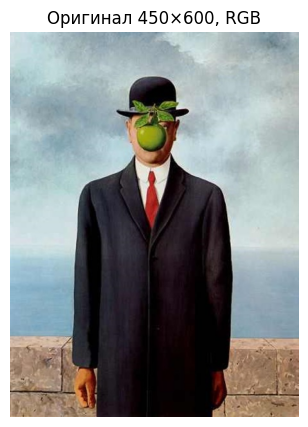

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.metrics import mean_squared_error

img = Image.open('most-famous-paintings-17.jpg').convert('RGB')
img_array = np.array(img)                      # uint8, (h, w, 3)
original_shape = img_array.shape
h, w, c = original_shape

print('Форма массива:', original_shape, '| dtype:', img_array.dtype)
print('Диапазон значений:', img_array.min(), '-', img_array.max())

plt.figure(figsize=(5, 5))
plt.imshow(img_array)
plt.title(f'Оригинал {w}×{h}, RGB')
plt.axis('off')
plt.show()

**Результат части А.** Изображение цветное, размер 450×600 (ширина × высота), т.е. подходит под усложнённое условие (≥300×300). Оно хранится как массив `uint8` формы (600, 450, 3): по одной матрице 600×450 на каждый канал R, G, B. Матрица не квадратная, поэтому максимальный ранг равен min(600, 450) = 450.

Картина удобна для эксперимента: на ней есть большие однородные области (тёмное пальто, светлое небо, море), мелкие детали (облака, каменная стена, листья) и небольшие яркие цветные объекты (зелёное яблоко, красный галстук).

## Часть Б. Применение SVD и восстановление

Разложение для каждого канала выполняется **один раз**, все три канала обрабатываются одним вызовом `np.linalg.svd` над массивом формы (3, h, w) (numpy раскладывает каждую матрицу стека). Восстановление ранга r выполняется через broadcasting: `(U[..., :r] * s[..., None, :r]) @ Vt[..., :r, :]`, без циклов и без `np.diag`.

In [2]:
# Каналы в отдельную ось: (3, h, w); float64 для точности разложения
channels = img_array.transpose(2, 0, 1).astype(np.float64)

t0 = time.time()
U, s, Vt = np.linalg.svd(channels, full_matrices=False)   # U:(3,h,k) s:(3,k) Vt:(3,k,w)
print(f'SVD для 3 каналов: {time.time() - t0:.2f} с')
print('U:', U.shape, ' s:', s.shape, ' Vt:', Vt.shape)

def reconstruct(U, s, Vt, r):
    """Аппроксимация ранга r для всех каналов сразу, результат (h, w, 3), обрезанный в [0, 255]."""
    A_r = (U[..., :r] * s[..., None, :r]) @ Vt[..., :r, :]   # (3, h, w)
    return np.clip(A_r.transpose(1, 2, 0), 0, 255)

list_of_ranks = [1, 5, 10, 30, 100, min(h, w)]
approximations = [reconstruct(U, s, Vt, r) for r in list_of_ranks]

# Проверка: полный ранг восстанавливает исходник (с точностью до округления)
print('Макс. отклонение при полном ранге:',
      np.abs(approximations[-1] - img_array).max())

SVD для 3 каналов: 0.23 с
U: (3, 600, 450)  s: (3, 450)  Vt: (3, 450, 450)
Макс. отклонение при полном ранге: 2.538058652135078e-11


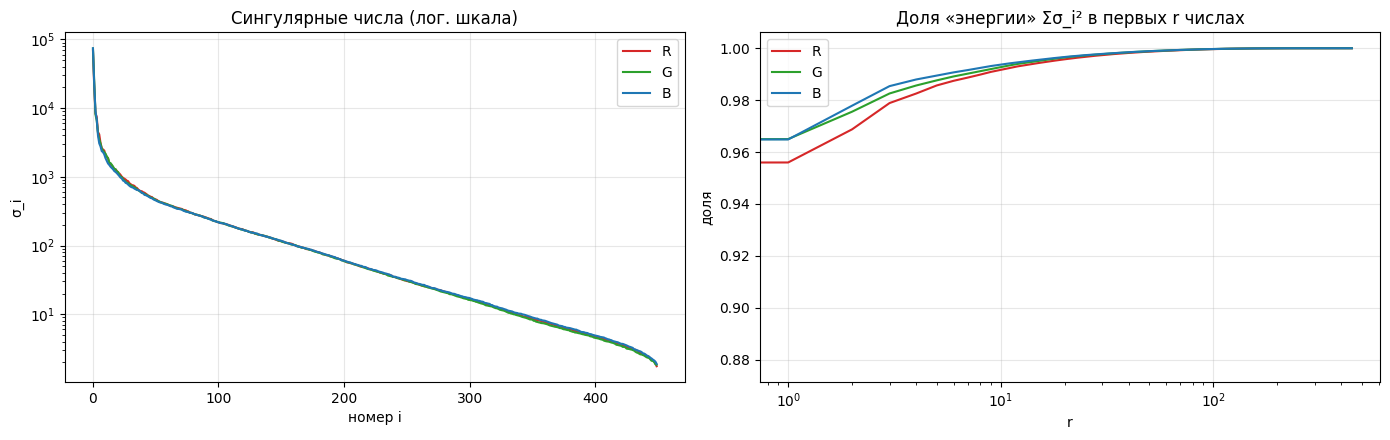

r =   1: доля энергии = 0.88024
r =   5: доля энергии = 0.98549
r =  10: доля энергии = 0.99205
r =  30: доля энергии = 0.99755
r = 100: доля энергии = 0.99968
r = 450: доля энергии = 1.00000


In [3]:
# Спектр сингулярных чисел по каналам
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ch, (name, col) in enumerate(zip('RGB', ['tab:red', 'tab:green', 'tab:blue'])):
    axes[0].semilogy(s[ch], color=col, label=name)
    energy = np.cumsum(s[ch] ** 2) / np.sum(s[ch] ** 2)
    axes[1].plot(energy, color=col, label=name)
axes[0].set(title='Сингулярные числа (лог. шкала)', xlabel='номер i', ylabel='σ_i')
axes[1].set(title='Доля «энергии» Σσ_i² в первых r числах', xlabel='r', ylabel='доля', xscale='log')
for ax in axes:
    ax.grid(True, alpha=0.3); ax.legend()
plt.tight_layout()
plt.show()

for r in list_of_ranks:
    e = (s[:, :r] ** 2).sum() / (s ** 2).sum()
    print(f'r = {r:3d}: доля энергии = {e:.5f}')

**Результат части Б.**

- SVD всех трёх каналов 600×450 занимает доли секунды. При полном ранге r = 450 изображение восстанавливается с отклонением ~1e-11, т.е. разложение точное и потерь нет.
- Сингулярные числа убывают очень быстро: первое число одно содержит ~88.0% «энергии» $\sum \sigma_i^2$ (это средний цвет/яркость по строкам и столбцам), первые 5 — ~98.5%, первые 10 — ~99.2%, первые 30 — ~99.8%, первые 100 — ~99.97%.
- Спектр убывает даже быстрее, чем у типичной фотографии. Картина состоит из крупных гладких областей, а многие границы на ней горизонтальные (линия горизонта, верх стены) или вертикальные (силуэт фигуры), и такие структуры хорошо описываются произведениями $u_i v_i^T$.
- Поэтому основная часть информации сосредоточена в небольшом числе первых компонент, а «хвост» спектра отвечает за мелкие детали и шум (в том числе за артефакты JPEG-сжатия исходного файла). На этом и основано сжатие.

## Часть В. Визуализация результатов

Коэффициент сжатия считается так, как описано в части Г (float32, 4 байта на число), здесь используется та же функция.

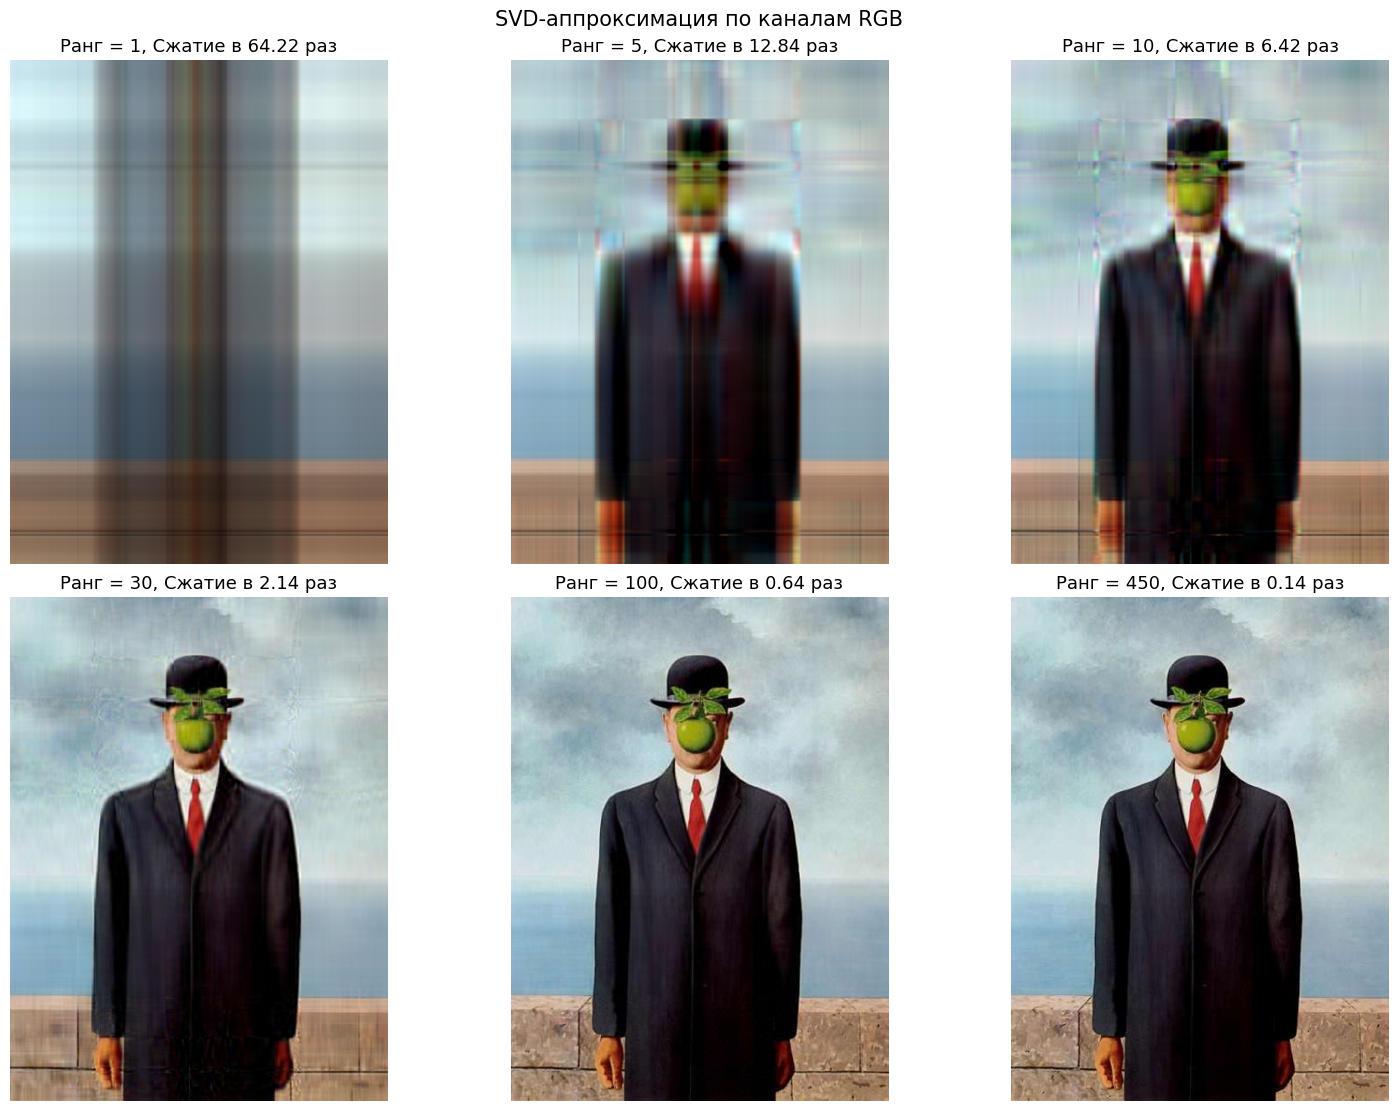

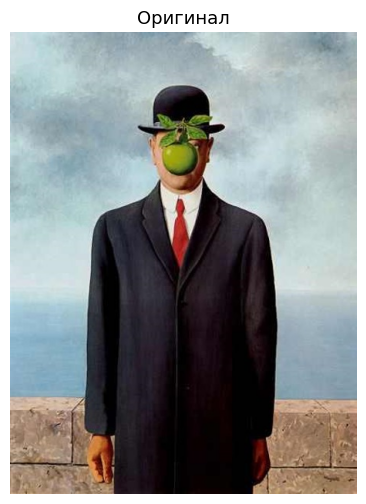

In [4]:
def compressed_bytes(r, h, w, channels=3, bytes_per_number=4):
    """Размер хранения U_r, Σ_r, V_r^T в байтах: r·(h + 1 + w) чисел на канал."""
    return channels * r * (h + 1 + w) * bytes_per_number

original_bytes = h * w * c          # 1 байт на канал
ratios = [original_bytes / compressed_bytes(r, h, w) for r in list_of_ranks]

fig, axes = plt.subplots(2, 3, figsize=(15, 11), layout='constrained')
for ax, r, A_r, k in zip(axes.flat, list_of_ranks, approximations, ratios):
    ax.imshow(A_r.astype(np.uint8))
    ax.set_title(f'Ранг = {r}, Сжатие в {k:.2f} раз', fontsize=13)
    ax.axis('off')
plt.suptitle('SVD-аппроксимация по каналам RGB', fontsize=15)
plt.show()

plt.figure(figsize=(6, 6))
plt.imshow(img_array)
plt.title('Оригинал', fontsize=13)
plt.axis('off')
plt.show()

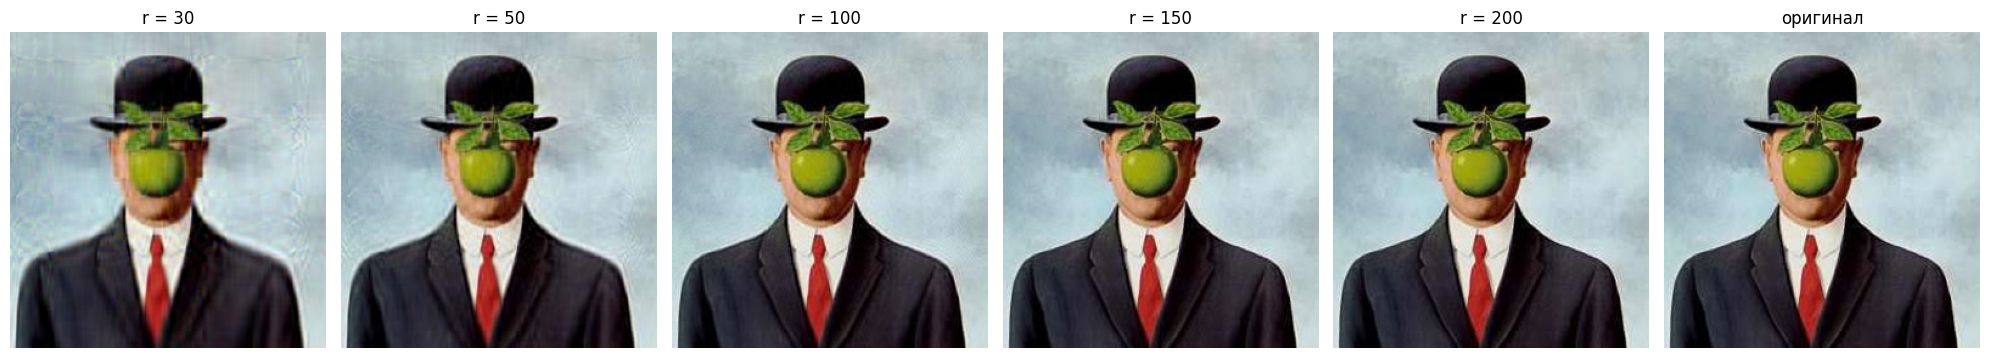

In [5]:
# Увеличенный фрагмент (шляпа, яблоко, галстук): здесь разница между рангами видна лучше всего
crop = (slice(50, 310), slice(100, 360))
show_ranks = [30, 50, 100, 150, 200]
fig, axes = plt.subplots(1, len(show_ranks) + 1, figsize=(20, 4))
for ax, r in zip(axes, show_ranks):
    ax.imshow(reconstruct(U, s, Vt, r)[crop].astype(np.uint8))
    ax.set_title(f'r = {r}'); ax.axis('off')
axes[-1].imshow(img_array[crop]); axes[-1].set_title('оригинал'); axes[-1].axis('off')
plt.tight_layout()
plt.show()

**Результат части В.**

- **r = 1**: изображение превращается в набор полос. Матрица ранга 1 — это внешнее произведение $\sigma_1 u_1 v_1^T$, т.е. все строки пропорциональны одной и той же строке. Поэтому видна только тёмная вертикальная полоса на месте фигуры и горизонтальные полосы неба, моря и стены.
- **r = 5**: фигура уже узнаётся: шляпа, пальто, красный галстук, зелёное пятно на месте яблока. Края сильно размыты, на небе видна цветная «рябь» из горизонтальных и вертикальных артефактов.
- **r = 10**: силуэт чётче, яблоко и шляпа различимы, но стена и облака почти без текстуры.
- **r = 30**: изображение выглядит хорошо, если смотреть на него целиком. На увеличенном фрагменте видны размытые края шляпы и пальто, «волны» на небе вокруг фигуры, а листья у яблока нечёткие.
- **r = 50–100**: на картинке целиком отличий от оригинала практически нет. При r = 100 текстура стены и облаков восстановлена, и даже на увеличенном фрагменте отличия почти незаметны.
- **r = 150–200**: на увеличенном фрагменте отличить от оригинала невозможно.
- **r = 450**: точное восстановление.

В подписях указан реальный коэффициент сжатия. Для r = 100 и r = 450 он **меньше 1**: хранить разложение в float32 *дороже*, чем исходный массив по 1 байту на канал (подробно — в части Г).

## Часть Г. Подсчёт эффективности сжатия

- Исходный размер: $3 \cdot h \cdot w$ байт (1 байт на канал).
- Сжатое представление: $3 \cdot r \cdot (h + 1 + w)$ чисел float32, т.е. $\times 4$ байта.
- Коэффициент сжатия: $K(r) = \dfrac{3hw}{3 \cdot 4 \cdot r(h+w+1)} = \dfrac{hw}{4r(h+w+1)}$.

Дополнительно считаем MSE и PSNR = $10\log_{10}(255^2/\text{MSE})$ — стандартную метрику качества изображения (> 30 дБ обычно считается хорошим качеством, > 40 дБ — почти неотличимым).

In [6]:
original_flat = img_array.flatten().astype(np.float64)

def psnr(mse):
    return np.inf if mse == 0 else 10 * np.log10(255 ** 2 / mse)

print(f'Исходный размер: {original_bytes} байт ({original_bytes / 1024:.0f} КБ)\n')
print(f'{"ранг":>5} | {"сжатый, байт":>13} | {"K (раз)":>8} | {"MSE":>9} | {"PSNR, дБ":>8}')
print('-' * 56)
for r, A_r, k in zip(list_of_ranks, approximations, ratios):
    m = mean_squared_error(original_flat, A_r.flatten())
    print(f'{r:5d} | {compressed_bytes(r, h, w):13d} | {k:8.2f} | {m:9.2f} | {psnr(m):8.2f}')

# Ранг, при котором сжатие ещё не меньше 10 раз
r_10 = int(np.floor(h * w / (4 * 10 * (h + w + 1))))
r_10_floats = int(np.floor(h * w / (10 * (h + w + 1))))   # если считать «1 число = 1 байт», без float32
print(f'\nСжатие ≥ 10 раз (float32): r ≤ {r_10}, при r = {r_10}: K = {original_bytes / compressed_bytes(r_10, h, w):.2f}')
print(f'Для справки, если хранить числа по 1 байту: r ≤ {r_10_floats}')
# Ранг, при котором «сжатие» становится расширением (K < 1)
r_1 = int(np.floor(h * w / (4 * (h + w + 1))))
print(f'K ≥ 1 только при r ≤ {r_1}')

Исходный размер: 810000 байт (791 КБ)

 ранг |  сжатый, байт |  K (раз) |       MSE | PSNR, дБ
--------------------------------------------------------
    1 |         12612 |    64.22 |   2647.56 |    13.90
    5 |         63060 |    12.84 |    315.88 |    23.14
   10 |        126120 |     6.42 |    172.14 |    25.77
   30 |        378360 |     2.14 |     53.12 |    30.88
  100 |       1261200 |     0.64 |      6.87 |    39.76
  450 |       5675400 |     0.14 |      0.00 |   288.38

Сжатие ≥ 10 раз (float32): r ≤ 6, при r = 6: K = 10.70
Для справки, если хранить числа по 1 байту: r ≤ 25
K ≥ 1 только при r ≤ 64


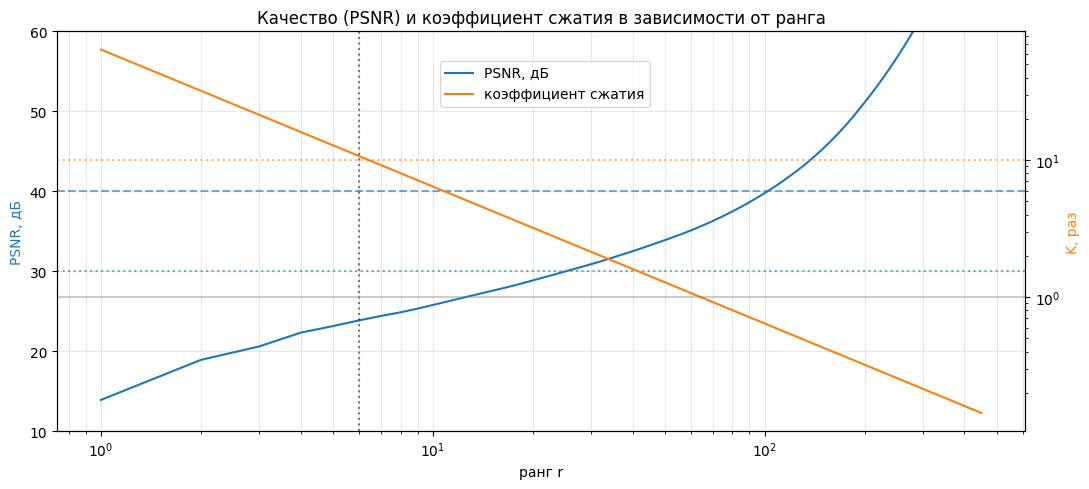

PSNR ≥ 25 дБ впервые при r =   9 (K = 7.14)
PSNR ≥ 30 дБ впервые при r =  26 (K = 2.47)
PSNR ≥ 35 дБ впервые при r =  60 (K = 1.07)
PSNR ≥ 40 дБ впервые при r = 103 (K = 0.62)


In [7]:
# Кривые качества и сжатия для всех рангов
all_r = np.arange(1, min(h, w) + 1)
mse_all, psnr_all = [], []
for r in all_r:
    A_r = reconstruct(U, s, Vt, r)
    m = np.mean((A_r - img_array) ** 2)
    mse_all.append(m); psnr_all.append(psnr(m))
K_all = original_bytes / np.array([compressed_bytes(r, h, w) for r in all_r])

fig, ax1 = plt.subplots(figsize=(11, 5))
ax1.plot(all_r, psnr_all, color='tab:blue', label='PSNR, дБ')
ax1.set_xlabel('ранг r'); ax1.set_ylabel('PSNR, дБ', color='tab:blue'); ax1.set_xscale('log')
ax1.set_ylim(10, 60)   # при полном ранге PSNR → ∞ (ошибка только от округления), обрезаем ось
ax1.axhline(30, color='tab:blue', ls=':', alpha=0.6)
ax1.axhline(40, color='tab:blue', ls='--', alpha=0.6)
ax2 = ax1.twinx()
ax2.plot(all_r, K_all, color='tab:orange', label='коэффициент сжатия')
ax2.set_ylabel('K, раз', color='tab:orange'); ax2.set_yscale('log')
ax2.axhline(10, color='tab:orange', ls=':', alpha=0.6); ax2.axhline(1, color='gray', ls='-', alpha=0.4)
ax1.axvline(r_10, color='k', ls=':', alpha=0.5)
ax1.grid(True, alpha=0.3, which='both')
plt.title('Качество (PSNR) и коэффициент сжатия в зависимости от ранга')
fig.legend(loc='upper center', bbox_to_anchor=(0.5, 0.88))
plt.tight_layout()
plt.show()

for target in (25, 30, 35, 40):
    r_t = all_r[np.argmax(np.array(psnr_all) >= target)]
    print(f'PSNR ≥ {target} дБ впервые при r = {r_t:3d} (K = {original_bytes / compressed_bytes(r_t, h, w):.2f})')

**Результат части Г.**

| ранг | K, раз | PSNR, дБ |
|---|---|---|
| 1 | 64.22 | 13.9 |
| 5 | 12.84 | 23.1 |
| 10 | 6.42 | 25.8 |
| 30 | 2.14 | 30.9 |
| 100 | 0.64 | 39.8 |
| 450 | 0.14 | ∞ (без потерь) |

- Коэффициент сжатия $K(r) = \dfrac{hw}{4r(h+w+1)} \approx \dfrac{64.2}{r}$ убывает обратно пропорционально рангу.
- **Сжатие в 10 раз** достигается при **r ≤ 6** (при r = 6 K ≈ 10.7). Качество при этом низкое, но картина узнаётся (PSNR ≈ 23.9 дБ). Если бы числа хранились по 1 байту (с квантованием), сжатие в 10 раз было бы при r ≤ 25.
- Сжатие вообще имеет смысл (K > 1) только при **r ≤ 64**. Дальше представление SVD становится *больше* исходного файла: каждая компонента стоит $h + w + 1 = 1051$ чисел на канал, а выигрыш даёт только отбрасывание компонент.
- Хорошее качество (PSNR ≥ 30 дБ) появляется уже при **r = 26 (K ≈ 2.5)**, а PSNR ≥ 35 дБ — при r = 60 (K ≈ 1.07). Значит, для этой картины **можно одновременно получить реальное сжатие и хорошее качество**: разумный компромисс — r ≈ 25–50 (K ≈ 1.3–2.5, PSNR ≈ 30–34 дБ).
- Так получается потому, что у картины спектр убывает очень быстро (крупные однородные области). Для обычной фотографии с большим количеством мелких деталей такой результат был бы хуже. В целом SVD без квантования проигрывает JPEG: исходный массив хранит всего 1 байт на канал, а мы храним факторы в 4-байтовом float32. Чтобы SVD был практичен, нужно квантовать $U$ и $V$ (8–16 бит).

## Дополнительно: почему ошибка различается на тёмных и светлых участках

Построим карту абсолютной ошибки и посчитаем среднюю ошибку в зависимости от яркости исходного пикселя.

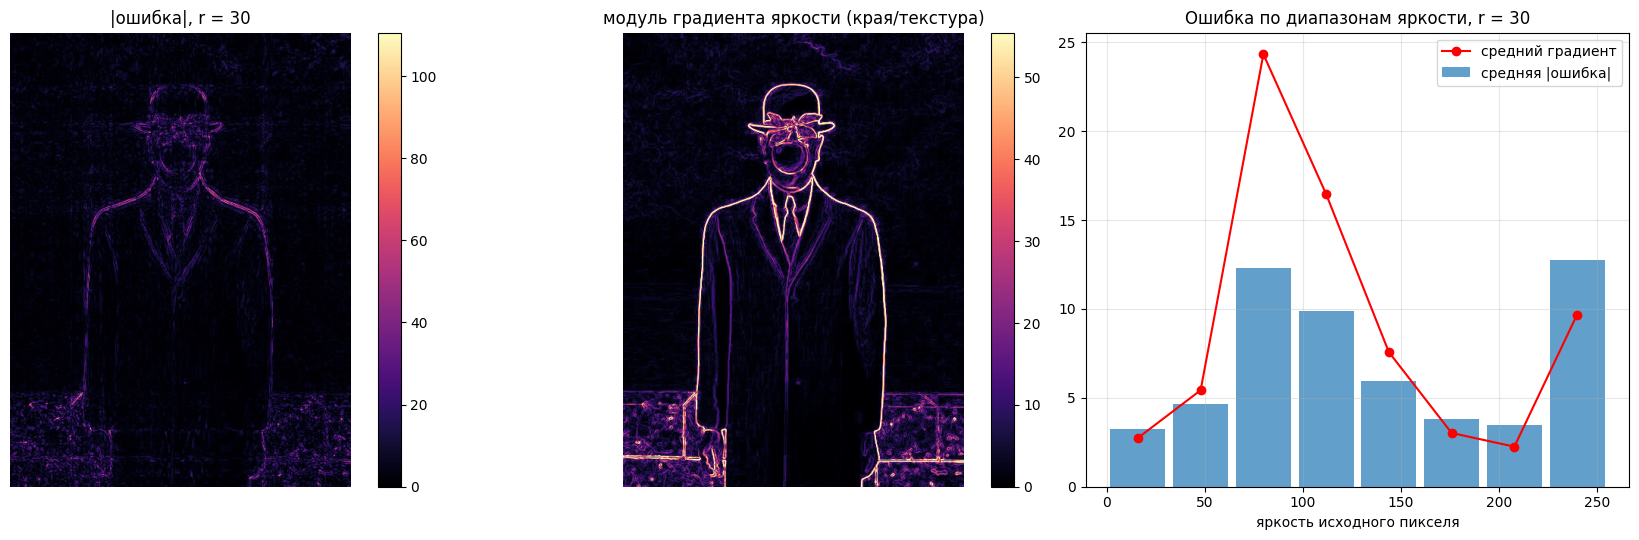

  яркость | доля пикс. | ср.|ошибка| | ср.градиент
       16 |      0.227 |        3.27 |        2.74
       48 |      0.105 |        4.66 |        5.43
       80 |      0.014 |       12.31 |       24.32
      112 |      0.033 |        9.86 |       16.46
      144 |      0.106 |        5.94 |        7.57
      176 |      0.266 |        3.82 |        3.02
      208 |      0.244 |        3.47 |        2.25
      240 |      0.004 |       12.76 |        9.68

Корреляция ошибки и градиента по пикселям: 0.51
Доля значений аппроксимации < 0: 0.0329, > 255: 0.0000


In [8]:
r_demo = 30
A_demo = reconstruct(U, s, Vt, r_demo)
err = np.abs(A_demo - img_array).mean(axis=2)                 # средняя по каналам абсолютная ошибка
brightness = img_array.astype(np.float64) @ [0.299, 0.587, 0.114]  # яркость пикселя

# Локальная «текстурность»: модуль градиента яркости
gy, gx = np.gradient(brightness)
grad = np.hypot(gx, gy)

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
im = axes[0].imshow(err, cmap='magma'); axes[0].set_title(f'|ошибка|, r = {r_demo}'); axes[0].axis('off')
plt.colorbar(im, ax=axes[0], fraction=0.046)
im = axes[1].imshow(grad, cmap='magma', vmax=np.percentile(grad, 99)); axes[1].set_title('модуль градиента яркости (края/текстура)'); axes[1].axis('off')
plt.colorbar(im, ax=axes[1], fraction=0.046)

bins = np.arange(0, 257, 32)
idx = np.digitize(brightness.ravel(), bins) - 1
centers, err_mean, grad_mean, share = [], [], [], []
for b in range(len(bins) - 1):
    m = idx == b
    if m.sum() > 0:
        centers.append((bins[b] + bins[b + 1]) / 2)
        err_mean.append(err.ravel()[m].mean()); grad_mean.append(grad.ravel()[m].mean())
        share.append(m.mean())
axes[2].bar(centers, err_mean, width=28, alpha=0.7, label='средняя |ошибка|')
axes[2].plot(centers, grad_mean, 'ro-', label='средний градиент')
axes[2].set(xlabel='яркость исходного пикселя', title=f'Ошибка по диапазонам яркости, r = {r_demo}')
axes[2].legend(); axes[2].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f'{"яркость":>9} | {"доля пикс.":>10} | {"ср.|ошибка|":>11} | {"ср.градиент":>11}')
for cc, sh, e, g in zip(centers, share, err_mean, grad_mean):
    print(f'{cc:9.0f} | {sh:10.3f} | {e:11.2f} | {g:11.2f}')
print('\nКорреляция ошибки и градиента по пикселям:', np.corrcoef(err.ravel(), grad.ravel())[0, 1].round(3))

# Сколько ошибки «срезает» обрезка в [0, 255] на тёмных/светлых пикселях
raw = ((U[..., :r_demo] * s[..., None, :r_demo]) @ Vt[..., :r_demo, :]).transpose(1, 2, 0)
print(f'Доля значений аппроксимации < 0: {(raw < 0).mean():.4f}, > 255: {(raw > 255).mean():.4f}')

**Ответ на вопрос «почему для тёмных и светлых участков ошибка разная».** На ранге r = 30:

- **Тёмные пиксели (яркость 0–32, ~23% изображения: пальто, шляпа)** имеют наименьшую ошибку (~3.3). Причины:
  1. это большая однородная область почти без деталей (средний градиент ~2.7), а однородную область хорошо описывают несколько первых компонент;
  2. значения ограничены снизу нулём: ~3.3% значений аппроксимации получились отрицательными и при обрезке в [0, 255] обнулились, т.е. «ошибка в минус» у тёмных пикселей частично срезается автоматически.
- **Светлые пиксели (160–224, ~51% изображения: небо, море)** тоже имеют малую ошибку (~3.5–3.8): небо — это плавные градиенты с мягкими облаками, градиент здесь минимальный (~2.3–3.0).
- **Средние тона (64–128)** имеют наибольшую ошибку (~10–12), хотя таких пикселей мало (~5%). Это в основном пиксели *на границах*: переход от тёмного пальто к светлому небу, складки пальто, тени на лице и руках, швы каменной стены. Средний градиент здесь максимальный (~16–24).
- **Самые светлые пиксели (224–255, ~0.4%)** снова имеют большую ошибку (~12.8). Это белая рубашка и воротник, т.е. маленькие яркие объекты с резким перепадом к тёмному пальто. Низкоранговая аппроксимация «размазывает» такие острые пики.

Общий принцип: ошибка определяется не яркостью как таковой, а **количеством мелких деталей и резких перепадов** (корреляция ошибки с градиентом по пикселям ≈ 0.51, карта ошибки повторяет карту контуров: силуэт пальто, шляпа, яблоко, стена). Первые сингулярные компоненты описывают крупные гладкие структуры, а края и текстура требуют многих компонент. На этой картине тёмные и светлые области — как раз крупные однородные зоны, а средние тона почти целиком лежат на границах между ними. Кроме того, человеческое зрение по закону Вебера–Фехнера заметнее воспринимает одинаковую абсолютную ошибку на тёмном фоне, поэтому шум на тёмном пальто визуально может бросаться в глаза даже при меньшем MSE.

## Автоматическая проверка (Self-Check)

In [9]:
# ---------- БЛОК АВТОПРОВЕРКИ (НЕ РЕДАКТИРОВАТЬ) ----------
# Предполагается, что у вас есть переменные:
# original_shape = (h, w, c) или (h, w)
# list_of_ranks = [1, 5, 10, 30, 100, ...]
# approximations = список восстановленных массивов (numpy) для каждого ранга

# 1. Проверка размерностей
for i, r in enumerate(list_of_ranks):
    assert approximations[i].shape == original_shape, f"Ошибка: размерность для ранга {r} не совпадает с исходной"

# 2. Проверка, что значения не выходят за пределы 0-255 (для RGB/серого)
for i, r in enumerate(list_of_ranks):
    arr = approximations[i]
    if arr.dtype != np.uint8:
        arr = np.clip(arr, 0, 255) # Если float, то проверяем диапазон
    assert arr.max() <= 255.1, f"Значения превышают 255 для ранга {r}"
    assert arr.min() >= -0.1, f"Значения меньше 0 для ранга {r}"

# 3. Проверка, что с ростом ранга ошибка уменьшается (метрика MSE)
from sklearn.metrics import mean_squared_error
mse_list = []
for i in range(len(approximations)):
    # Если цветная, считаем MSE по всем каналам
    mse = mean_squared_error(original_flat, approximations[i].flatten())
    mse_list.append(mse)

# Проверяем монотонность (MSE должен падать, так как мы добавляем сингулярные числа)
for i in range(1, len(mse_list)):
    assert mse_list[i] <= mse_list[i-1] + 1e-6, f"MSE не уменьшается между рангами {list_of_ranks[i-1]} и {list_of_ranks[i]}"

print("✅ Все автоматические проверки пройдены. Задание выполнено корректно!")

✅ Все автоматические проверки пройдены. Задание выполнено корректно!


## Выводы

1. **SVD даёт оптимальную низкоранговую аппроксимацию** (теорема Эккарта–Янга): ошибка монотонно убывает с ростом ранга, что подтвердила автопроверка, а при полном ранге изображение восстанавливается без потерь.
2. **Спектр картины убывает очень быстро**: 1 компонента содержит ~88% энергии, 5 — ~98.5%, 100 — ~99.97%. Поэтому изображение узнаётся уже при r ≈ 5, при **r ≈ 30 (PSNR ≈ 31 дБ)** хорошо выглядит целиком, а при r ≈ 50–100 (PSNR ≈ 34–40 дБ) визуально почти не отличается от оригинала. На увеличенном фрагменте разница исчезает при r ≈ 150 (PSNR ≈ 45 дБ).
3. **Сжатие в 10 раз** (float32) получается при **r = 6** (PSNR ≈ 24 дБ — картина узнаётся, но сильно размыта). Реальное сжатие (K > 1) возможно при r ≤ 64, а хорошее качество (PSNR ≥ 30 дБ) достигается уже при r = 26. Для этой картины эти условия совпадают: при r ≈ 25–50 получаем сжатие в 1.3–2.5 раза с хорошим качеством. Это заслуга крупных однородных областей и горизонтально-вертикальной композиции. Для фотографии с большим количеством мелких деталей результат был бы хуже, а в целом SVD без квантования факторов не конкурирует с JPEG.
4. **Ошибка распределена неравномерно**: она сосредоточена на краях и текстуре (контур пальто, шляпа, яблоко, рубашка, каменная стена), а большие однородные области — тёмное пальто и светлое небо — восстанавливаются лучше всего.
5. **Реализация**: выполнен продвинутый вариант — SVD для каждого из каналов RGB отдельно. Все три канала раскладываются одним вызовом `np.linalg.svd` над стеком (3, h, w), а восстановление делается через broadcasting `(U[..., :r] * s[..., None, :r]) @ Vt[..., :r, :]`, без циклов по каналам и без `np.diag`. Разложение занимает доли секунды, восстановление для каждого ранга — миллисекунды.